In [8]:
import pandas as pd
import numpy as np
from pathlib import Path
import re
import unicodedata

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [2]:
BASE = Path.cwd().parent          # data/
RAW_SINAN = BASE / "dados" / "bruto" / "sinan"
RAW_INMET = BASE / "dados" / "bruto" / "inmet"
PROCESSED = BASE / "processed"
PROCESSED.mkdir(exist_ok=True)

print(RAW_SINAN.exists(), sorted(p.name for p in RAW_SINAN.glob("*.csv")))

True ['DENGBR20.csv', 'DENGBR21.csv', 'DENGBR22.csv', 'DENGBR23.csv', 'DENGBR24.csv', 'DENGBR25.csv']


In [3]:
amostra = pd.read_csv(RAW_SINAN / "DENGBR25.csv", nrows=5, low_memory=False)
print(amostra.shape)
print(list(amostra.columns))

(5, 121)
['TP_NOT', 'ID_AGRAVO', 'DT_NOTIFIC', 'SEM_NOT', 'NU_ANO', 'SG_UF_NOT', 'ID_MUNICIP', 'ID_REGIONA', 'ID_UNIDADE', 'DT_SIN_PRI', 'SEM_PRI', 'ANO_NASC', 'NU_IDADE_N', 'CS_SEXO', 'CS_GESTANT', 'CS_RACA', 'CS_ESCOL_N', 'SG_UF', 'ID_MN_RESI', 'ID_RG_RESI', 'ID_PAIS', 'DT_INVEST', 'ID_OCUPA_N', 'FEBRE', 'MIALGIA', 'CEFALEIA', 'EXANTEMA', 'VOMITO', 'NAUSEA', 'DOR_COSTAS', 'CONJUNTVIT', 'ARTRITE', 'ARTRALGIA', 'PETEQUIA_N', 'LEUCOPENIA', 'LACO', 'DOR_RETRO', 'DIABETES', 'HEMATOLOG', 'HEPATOPAT', 'RENAL', 'HIPERTENSA', 'ACIDO_PEPT', 'AUTO_IMUNE', 'DT_CHIK_S1', 'DT_CHIK_S2', 'DT_PRNT', 'RES_CHIKS1', 'RES_CHIKS2', 'RESUL_PRNT', 'DT_SORO', 'RESUL_SORO', 'DT_NS1', 'RESUL_NS1', 'DT_VIRAL', 'RESUL_VI_N', 'DT_PCR', 'RESUL_PCR_', 'SOROTIPO', 'HISTOPA_N', 'IMUNOH_N', 'HOSPITALIZ', 'DT_INTERNA', 'UF', 'MUNICIPIO', 'TPAUTOCTO', 'COUFINF', 'COPAISINF', 'COMUNINF', 'CLASSI_FIN', 'CRITERIO', 'DOENCA_TRA', 'CLINC_CHIK', 'EVOLUCAO', 'DT_OBITO', 'DT_ENCERRA', 'ALRM_HIPOT', 'ALRM_PLAQ', 'ALRM_VOM', 'ALR

In [4]:
COLUNAS = ["DT_NOTIFIC", "SEM_NOT", "NU_ANO", "SG_UF_NOT", "ID_MUNICIP", "CLASSI_FIN"]
UF = None   # coloque o código da UF (ex.: 22) para filtrar um estado; None = Brasil inteiro

dfs = []
for arq in sorted(RAW_SINAN.glob("DENGBR*.csv")):
    df = pd.read_csv(arq, usecols=lambda c: c in COLUNAS, low_memory=False)
    if UF is not None:
        df = df[df["SG_UF_NOT"] == UF]
    dfs.append(df)
    print(arq.name, len(df))

sinan = pd.concat(dfs, ignore_index=True)
sinan["DT_NOTIFIC"] = pd.to_datetime(sinan["DT_NOTIFIC"], errors="coerce")
sinan = sinan.dropna(subset=["DT_NOTIFIC"])
sinan.to_csv(PROCESSED / "sinan_tratado.csv", index=False)
sinan.info()

DENGBR20.csv 1495117
DENGBR21.csv 1024635
DENGBR22.csv 1405095
DENGBR23.csv 1645956
DENGBR24.csv 6564924
DENGBR25.csv 1643215
<class 'pandas.DataFrame'>
RangeIndex: 13778942 entries, 0 to 13778941
Data columns (total 6 columns):
 #   Column      Dtype         
---  ------      -----         
 0   DT_NOTIFIC  datetime64[us]
 1   SEM_NOT     int64         
 2   NU_ANO      int64         
 3   SG_UF_NOT   int64         
 4   ID_MUNICIP  int64         
 5   CLASSI_FIN  float64       
dtypes: datetime64[us](1), float64(1), int64(4)
memory usage: 630.8 MB


Celula 4

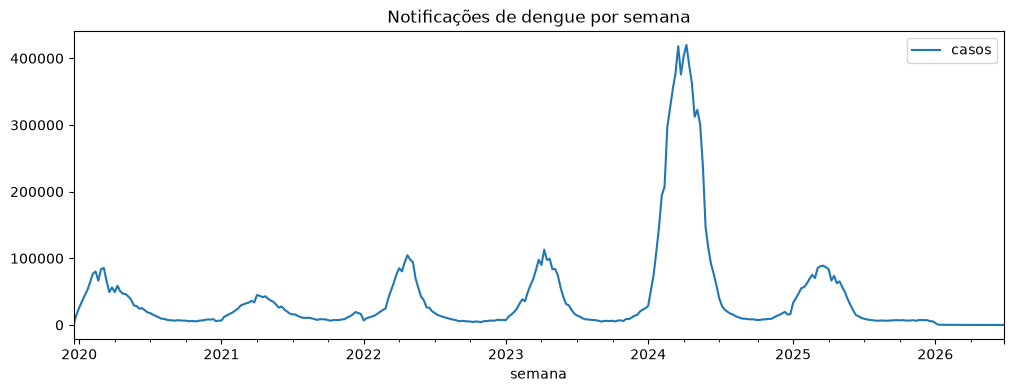

In [8]:
semanal = (sinan
           .assign(semana=sinan["DT_NOTIFIC"].dt.to_period("W").dt.start_time)
           .groupby("semana").size().rename("casos").reset_index())
semanal.plot(x="semana", y="casos", figsize=(12, 4), title="Notificações de dengue por semana");

Ok so um teste.

In [6]:
BASE = Path.cwd().parent
RAW_INMET = BASE / "dados" / "bruto" / "inmet"
PROCESSED = BASE / "processed"

UF_SIGLA = None   # ex.: "PI" para filtrar um estado; None = todas as estações

def ler_estacao(arq):
    # cabeçalho: 8 linhas de metadados
    with open(arq, encoding="latin-1") as f:
        meta = [next(f).split(";")[1].strip() for _ in range(8)]
    uf, estacao, codigo = meta[1], meta[2], meta[3]
    lat = float(meta[4].replace(",", "."))
    lon = float(meta[5].replace(",", "."))

    df = pd.read_csv(arq, sep=";", skiprows=8, encoding="latin-1",
                     decimal=",", usecols=[0, 1, 2],
                     names=["data", "hora", "chuva_mm"], header=0)
    df["data"] = pd.to_datetime(df["data"].astype(str).str.replace("/", "-"), errors="coerce")
    df["chuva_mm"] = pd.to_numeric(df["chuva_mm"], errors="coerce")
    df.loc[df["chuva_mm"] <= -999, "chuva_mm"] = np.nan   # -9999 = sem medição
    df = df.dropna(subset=["data"])

    semanal = (df.groupby(df["data"].dt.to_period("W-SAT").dt.start_time)["chuva_mm"]
                 .agg(chuva_semana_mm="sum", horas_validas="count")
                 .reset_index().rename(columns={"data": "semana"}))
    semanal["uf"], semanal["estacao"], semanal["codigo"] = uf, estacao, codigo
    semanal["lat"], semanal["lon"] = lat, lon
    return semanal

partes = []
for arq in sorted(RAW_INMET.rglob("*.csv")):
    try:
        s = ler_estacao(arq)
    except Exception as e:
        print("Erro em", arq.name, "->", e)
        continue
    if UF_SIGLA is None or s["uf"].iloc[0] == UF_SIGLA:
        partes.append(s)

inmet = pd.concat(partes, ignore_index=True)
print(inmet.shape, inmet["estacao"].nunique(), "estações")
inmet.head()

(182712, 8) 635 estações


,semana,chuva_semana_mm,horas_validas,uf,estacao,codigo,lat,lon
0,2019-12-29,51.4,96,DF,BRASILIA,A001,-15.789343,-47.925756
1,2020-01-05,74.2,168,DF,BRASILIA,A001,-15.789343,-47.925756
2,2020-01-12,1.6,168,DF,BRASILIA,A001,-15.789343,-47.925756
3,2020-01-19,77.4,168,DF,BRASILIA,A001,-15.789343,-47.925756
4,2020-01-26,106.4,168,DF,BRASILIA,A001,-15.789343,-47.925756


In [7]:
# limites em mm por semana (ajuste conforme o critério do trabalho)
inmet["nivel_chuva"] = pd.cut(
    inmet["chuva_semana_mm"],
    bins=[-np.inf, 0, 10, 50, np.inf],
    labels=["sem chuva", "fraca", "moderada", "forte"],
)

# semanas com muitas horas sem medição ficam pouco confiáveis
inmet["semana_confiavel"] = inmet["horas_validas"] >= 120   # de 168 h

inmet.to_csv(PROCESSED / "inmet_semanal_estacoes.csv", index=False)
inmet["nivel_chuva"].value_counts()

nivel_chuva
sem chuva    85800
moderada     38024
fraca        36122
forte        22766
Name: count, dtype: int64

Teste 2

In [ ]:
# Diretório principal do projeto
BASE_DIR = Path.cwd()

# Diretórios dos dados
PASTA_BRUTOS = BASE_DIR / "dados" / "brutos"
PASTA_HORARIOS = BASE_DIR / "dados" / "tratados" / "horarios"
PASTA_SEMANAIS = BASE_DIR / "dados" / "tratados" / "semanais"

# Criar pastas automaticamente
PASTA_HORARIOS.mkdir(parents=True, exist_ok=True)
PASTA_SEMANAIS.mkdir(parents=True, exist_ok=True)

ANOS = range(2020, 2026)

print("Diretórios configurados!")

Diretórios configurados!


In [10]:
def limpar_nome_coluna(nome):

    nome = str(nome).strip().lower()

    nome = unicodedata.normalize(
        "NFKD", nome
    ).encode("ascii", "ignore").decode("utf-8")

    nome = re.sub(r"[^a-z0-9]+", "_", nome)

    return nome.strip("_")

In [11]:
def tratar_csv(caminho):

    # Arquivos históricos automáticos do INMET
    df = pd.read_csv(
        caminho,
        sep=";",
        encoding="latin1",
        skiprows=8,
        decimal=","
    )

    # Limpar nomes das colunas
    df.columns = [
        limpar_nome_coluna(col)
        for col in df.columns
    ]

    # Identificar colunas
    coluna_data = next(
        (c for c in df.columns if c.startswith("data")),
        None
    )

    coluna_hora = next(
        (c for c in df.columns if c.startswith("hora")),
        None
    )

    coluna_chuva = next(
        (
            c for c in df.columns
            if "precipitacao" in c and "horario" in c
        ),
        None
    )

    if not all([coluna_data, coluna_hora, coluna_chuva]):
        raise ValueError(
            f"Colunas necessárias não encontradas: {df.columns.tolist()}"
        )

    # Converter data
    data = pd.to_datetime(
        df[coluna_data],
        errors="coerce",
        dayfirst=False
    )

    # Extrair hora no padrão HHMM
    hora = (
        df[coluna_hora]
        .astype(str)
        .str.extract(r"(\d{1,4})")[0]
        .str.zfill(4)
    )

    # Montar data e hora
    df["data_hora"] = pd.to_datetime(
        data.dt.strftime("%Y-%m-%d") + " " + hora,
        format="%Y-%m-%d %H%M",
        errors="coerce"
    )

    # Converter precipitação
    df["precipitacao_mm"] = pd.to_numeric(
        df[coluna_chuva],
        errors="coerce"
    )

    # Tratar valores inválidos
    df.loc[
        df["precipitacao_mm"] == -9999,
        "precipitacao_mm"
    ] = np.nan

    # Identificar código da estação pelo nome do arquivo
    partes = caminho.stem.split("_")

    df["codigo_estacao"] = (
        partes[3] if len(partes) > 3 else caminho.stem
    )

    # Remover registros sem data ou hora
    df = df.dropna(subset=["data_hora"])

    # Selecionar informações importantes
    df = df[
        [
            "codigo_estacao",
            "data_hora",
            "precipitacao_mm"
        ]
    ]

    return df

In [12]:
arquivos = []

for arquivo in PASTA_BRUTOS.rglob("*"):
    if arquivo.suffix.lower() == ".csv":
        arquivos.append(arquivo)

print(f"Arquivos encontrados: {len(arquivos)}")

Arquivos encontrados: 0


In [13]:
dados_tratados = []
erros = []

for arquivo in arquivos:

    try:
        df = tratar_csv(arquivo)

        dados_tratados.append(df)

        print(f"Processado: {arquivo.name}")

    except Exception as erro:

        erros.append({
            "arquivo": arquivo.name,
            "erro": str(erro)
        })

# Juntar todos os arquivos
if dados_tratados:

    dados_inmet = pd.concat(
        dados_tratados,
        ignore_index=True
    )

    # Remover duplicações
    dados_inmet = dados_inmet.drop_duplicates(
        subset=["codigo_estacao", "data_hora"]
    )

    # Ordenar dados
    dados_inmet = dados_inmet.sort_values(
        ["codigo_estacao", "data_hora"]
    ).reset_index(drop=True)

    print("\nTratamento concluído!")
    print(f"Total de registros: {len(dados_inmet)}")

else:
    raise ValueError("Nenhum arquivo foi processado.")

# Exibir arquivos com problemas
if erros:
    print("\nArquivos que precisam de atenção:")
    for erro in erros:
        print(erro)

ValueError: Nenhum arquivo foi processado.

In [ ]:
dados_inmet["ano"] = dados_inmet["data_hora"].dt.year

for ano in ANOS:

    dados_ano = dados_inmet[
        dados_inmet["ano"] == ano
    ].copy()

    if not dados_ano.empty:

        caminho = PASTA_HORARIOS / f"inmet_horario_{ano}.csv"

        dados_ano.to_csv(
            caminho,
            index=False,
            encoding="utf-8-sig"
        )

        print(f"Ano {ano} salvo: {len(dados_ano)} registros")